*Carga de Datos*


In [6]:
%pip install networkx

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------- ----- 1.8/2.1 MB 12.4 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 9.7 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import networkx as nx

In [21]:
# 1. Cargar el dataset
df = pd.read_csv('online_shoppers_intention.csv')

# 2. Filtrar unicamente las entradas y la salida requeridas
columnas = ['VisitorType', 'ProductRelated', 'ProductRelated_Duration', 'Revenue']
df = df[columnas]

# Mostrar las primeras filas para confirmar la carga exitosa
df.head()

,VisitorType,ProductRelated,ProductRelated_Duration,Revenue
0,Returning_Visitor,1,0.000000,False
1,Returning_Visitor,2,64.000000,False
2,Returning_Visitor,1,0.000000,False
3,Returning_Visitor,2,2.666667,False
4,Returning_Visitor,10,627.500000,False


### Interpretación del Dataset
Cada registro en este conjunto de datos corresponde a una sesión de navegación individual en la tienda en línea. Las variables seleccionadas para este proyecto representan lo siguiente:

* **VisitorType:** Indica el perfil del usuario, principalmente si es un visitante recurrente (`Returning_Visitor`) o un usuario nuevo (`New_Visitor`).
* **ProductRelated:** Representa la cantidad total de páginas de productos que el usuario visitó durante esa sesión.
* **ProductRelated_Duration:** Es el tiempo total que el visitante pasó navegando específicamente en esas páginas relacionadas con productos.
* **Revenue:** Es la variable de salida (la clase a predecir). Un valor de `True` significa que la sesión terminó exitosamente en una compra, mientras que `False` indica que el usuario abandonó la tienda sin comprar.

### 1. Revisión de Datos Faltantes
Se verifica la existencia de valores nulos en las variables de entrada y salida, eliminando aquellas sesiones incompletas para asegurar que los modelos reciban información válida.

### 2. Distribución de la Clase (Revenue)
Se visualiza mediante un gráfico de barras y se calcula la proporción exacta de sesiones que culminaron en compra frente a las que no. Esto permite conocer el balance de la clase a estimar.El True indica que hubo una compra y false que en la visita no hubi compra

### 3. Partición de Datos (80/20)
Se divide el conjunto total reservando el 80% de las sesiones para ajustar las transformaciones y entrenar los modelos, dejando un 20% intacto para la prueba final. Se utiliza una semilla fija para garantizar la reproducción de los resultados y una partición estratificada (`stratify=y`) para mantener la proporción de compras idéntica en ambos subconjuntos.

-- Datos faltantes por columna ---
VisitorType                0
ProductRelated             0
ProductRelated_Duration    0
Revenue                    0
dtype: int64


C:\Users\Yael\AppData\Local\Temp\ipykernel_25064\1468962305.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df , x='Revenue' , palette='viridis')


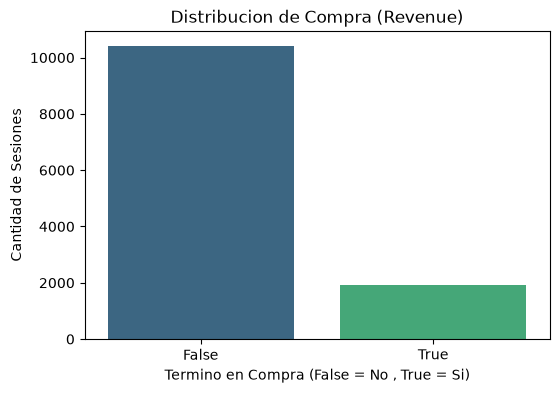


--- Proporción de compras (%) ---
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64

Sesiones para entrenamiento: 9864 (80%)
Sesiones para prueba: 2466 (20%)


In [22]:
# 1. Revision de datos faltantes

print("-- Datos faltantes por columna ---")
print(df.isnull().sum())

# Eliminas filas con nulos (Si hay)
df=df.dropna()

# 2. Explorar y representar la distribucion de compra
plt.figure(figsize=(6,4))
sns.countplot(data=df , x='Revenue' , palette='viridis')
plt.title('Distribucion de Compra (Revenue)')
plt.xlabel('Termino en Compra (False = No , True = Si)')
plt.ylabel('Cantidad de Sesiones')
plt.show()

# Proporcion Exacta
print("\n--- Proporción de compras (%) ---")
print(df['Revenue'].value_counts(normalize=True) * 100)


# 3. Particion de datos ( 80% Entrenamiento y 20% Prueba)
X = df[['VisitorType', 'ProductRelated', 'ProductRelated_Duration']]
y = df['Revenue']

# Se utiliza stratify=y para asegurar que la proporcion de compras se mantenga
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nSesiones para entrenamiento: {len(X_train)} (80%)")
print(f"Sesiones para prueba: {len(X_test)} (20%)")

### 4. Categorización para la Red Naive Bayes (P33 y P67)
Se dividen las sesiones en tres grupos de tamaño equitativo (terciles) utilizando los percentiles 33 y 67 calculados de manera estricta sobre el conjunto de entrenamiento. Esto previene la fuga de información (data leakage). Estas etiquetas ("bajo", "medio", "alto") se aplican al conjunto de prueba y simplifican las tablas de probabilidades condicionales de la red bayesiana al evitar probabilidades nulas por valores numéricos exactos no observados.

In [23]:
# 4. Categorizar para la red Navie Bayes
# Se calculan especificamnet P33 y P67 unicamente con los datos de entrenamiento 

p33_pr= X_train['ProductRelated'].quantile(0.33)
p67_pr= X_train['ProductRelated'].quantile(0.67)

p33_dur = X_train['ProductRelated_Duration'].quantile(0.33)
p67_dur = X_train['ProductRelated_Duration'].quantile(0.67)

print("--- Cortes para ProductRelated ---")
print(f"Bajo: <= {p33_pr:.2f} | Medio: hasta {p67_pr:.2f} | Alto: > {p67_pr:.2f}")
print("\n--- Cortes para ProductRelated_Duration ---")
print(f"Bajo: <= {p33_dur:.2f} | Medio: hasta {p67_dur:.2f} | Alto: > {p67_dur:.2f}")

def categorizar(x,p33,p67):
    if x <= p33:
        return 'Bajo'
    elif p33 < x <= p67:
        return 'Medio'
    else:
        return 'Alto'
    
#Creamos copias independientes para conservar los datos numericos intactos
X_train_cat = X_train.copy()
X_test_cat = X_test.copy()

#Aplicar los cortes a las columnas correspondientes en entrenamiento y prueba
for df_cat in [X_train_cat, X_test_cat]:
    df_cat['ProductRelated'] = df_cat['ProductRelated'].apply(lambda x: categorizar(x, p33_pr, p67_pr))
    df_cat['ProductRelated_Duration'] = df_cat['ProductRelated_Duration'].apply(lambda x: categorizar(x, p33_dur, p67_dur))
    
print("\n--- Ejemplo de las sesiones categorizadas (X_train_cat) ---")
print(X_train_cat.head())

--- Cortes para ProductRelated ---
Bajo: <= 10.00 | Medio: hasta 29.00 | Alto: > 29.00

--- Cortes para ProductRelated_Duration ---
Bajo: <= 285.93 | Medio: hasta 1107.23 | Alto: > 1107.23

--- Ejemplo de las sesiones categorizadas (X_train_cat) ---
            VisitorType ProductRelated ProductRelated_Duration
4263  Returning_Visitor           Alto                    Alto
5905  Returning_Visitor           Bajo                    Bajo
9434  Returning_Visitor           Bajo                    Bajo
3505  Returning_Visitor          Medio                    Alto
2067  Returning_Visitor           Alto                   Medio


### 5. Preparación de Datos Numéricos para Machine Learning
Para los modelos Random Forest y MLP, es necesario conservar las cantidades y duraciones numéricas originales del dataset sin categorizarlas[cite: 1]. 

En esta etapa realizamos dos transformaciones clave asegurando que ambas se ajusten **exclusivamente con los datos de entrenamiento** para evitar la fuga de información (data leakage):
1. **Codificación:** Transformamos la variable categórica `VisitorType` a valores numéricos usando `LabelEncoder`.
2. **Escalado:** Estandarizamos las entradas numéricas `ProductRelated` y `ProductRelated_Duration` con `StandardScaler`, lo cual es un requisito indispensable para el correcto funcionamiento de la red neuronal (MLP).

In [24]:
# 5. Preparación de datos numéricos para Machine Learning (Random Forest y MLP)
# Se conservan las cantidades numéricas originales copiando los datos
X_train_num = X_train.copy()
X_test_num = X_test.copy()

# Codificación de VisitorType ajustando solo con entrenamiento
encoder = LabelEncoder()
X_train_num['VisitorType'] = encoder.fit_transform(X_train_num['VisitorType'])
# Se transforma prueba con las categorías aprendidas en entrenamiento
X_test_num['VisitorType'] = encoder.transform(X_test_num['VisitorType'])

# Escalado de entradas numéricas para el MLP (usaremos StandardScaler)
# El escalador se ajusta EXCLUSIVAMENTE con el conjunto de entrenamiento
scaler = StandardScaler()
cols_a_escalar = ['ProductRelated', 'ProductRelated_Duration'] 

X_train_num[cols_a_escalar] = scaler.fit_transform(X_train_num[cols_a_escalar])
X_test_num[cols_a_escalar] = scaler.transform(X_test_num[cols_a_escalar])

print("--- Ejemplo de las sesiones numéricas preparadas (X_train_num) ---")
print(X_train_num.head())

--- Ejemplo de las sesiones numéricas preparadas (X_train_num) ---
      VisitorType  ProductRelated  ProductRelated_Duration
4263            2        0.058405                 0.083393
5905            2       -0.629459                -0.539163
9434            2       -0.629459                -0.599504
3505            2       -0.331385                 0.009963
2067            2        0.012548                -0.187989


### 6. Teorema de Bayes por conteos: P(Compra | Recurrente)
Se calculará la probabilidad de que una sesión termine en compra ($C$) dado que el usuario es un visitante recurrente ($R$). 
De acuerdo con las reglas del proyecto, los conteos se realizan exclusivamente sobre el conjunto de entrenamiento.

**Fórmula de Bayes:**
P(C|R) = \frac{P(R|C) \times P(C)}{P(R)}$$



In [25]:
# 6. Calculo de P(Compra | Recurrente) con el Teorrema de Bayes
#Unir X_Train y y_train temporalmente para facilitar los filtros

df_train= X_train.copy()
df_train['Revenue'] = y_train

#Total de sesiones en el entrenamiento
total_sesiones = len(df_train)

#Definir Compras y Recurrente
compras = df_train[df_train['Revenue']== True]
reccurrentes = df_train[df_train['VisitorType'] == 'Returning_Visitor']

#Calcular las probabilidades individuales requeridas para la formula
#P(C) -> Probabilidad de Compra
p_c= len(compras)/total_sesiones
#P(R) -> Probabilidad de Visitante Recurrente
p_r=len(reccurrentes) / total_sesiones


# P(R|C) -> Probabilidad de ser Recurrente dado que ya compro
reccurrentes_y_compran= df_train[(df_train['VisitorType']== 'Returning_Visitor') & (df_train['Revenue']==True)]
p_r_dado_c= len(reccurrentes_y_compran)/len(compras)

#Aplicar Teorema de Bayes
bayes_p_c_dado_r=(p_r_dado_c*p_c)/p_r

#Comprobacion mediante conteo directo
conteo=len(reccurrentes_y_compran)/len(reccurrentes)


#Impresion

print("------- Sustitucion y calculos con el Teorema de Bayes -------")
print(f"P(C) = {p_c:.4f}")
print(f"P(R) = {p_r:.4f}")
print(f"P(C|R) = {p_r_dado_c:.4f}")
print(f"Fórmula: ({p_r_dado_c:.4f} * {p_c:.4f}) / {p_r:.4f}")
print(f"Resultado Bayes: P(Compra | Recurrente) = {bayes_p_c_dado_r:.4f}")

print("\n--- Comprobación mediante conteo directo ---")
print(f"Sesiones recurrentes que compraron: {len(reccurrentes_y_compran)}")
print(f"Total de sesiones recurrentes: {len(reccurrentes)}")
print(f"Resultado Directo ({len(reccurrentes_y_compran)} / {len(reccurrentes)}) = {conteo:.4f}")


if round(bayes_p_c_dado_r, 4) == round(conteo, 4):
    print("Calculo Exitoso")

------- Sustitucion y calculos con el Teorema de Bayes -------
P(C) = 0.1547
P(R) = 0.8559
P(C|R) = 0.7733
Fórmula: (0.7733 * 0.1547) / 0.8559
Resultado Bayes: P(Compra | Recurrente) = 0.1398

--- Comprobación mediante conteo directo ---
Sesiones recurrentes que compraron: 1180
Total de sesiones recurrentes: 8443
Resultado Directo (1180 / 8443) = 0.1398
Calculo Exitoso


### 7. Construcción de la Red Naive Bayes y Tablas de Probabilidad
En este apartado se define la estructura gráfica del modelo asumiendo la premisa de **"Naive Bayes" (Bayes Ingenuo)**: la variable objetivo `Revenue` (Compra) actúa como el nodo padre que influye directamente sobre las variables predictoras (`VisitorType`, `ProductRelated` y `ProductRelated_Duration`), asumiendo que estas son **condicionalmente independientes** entre sí.

Para calcular las tablas de probabilidad condicional, se aplica el **suavizado de Laplace** (sumando 1 a cada conteo). Esto es indispensable para evitar asignar una probabilidad de cero absoluto a eventos o combinaciones de categorías que no aparecieron en el conjunto de entrenamiento, garantizando que el modelo sea robusto al evaluar datos nuevos.

--- Tabla Condicional: VisitorType | Compra ---
Revenue               False     True 
VisitorType                          
New_Visitor        0.121688  0.218443
Other              0.007433  0.009156
Returning_Visitor  0.870879  0.772400

--- Tabla Condicional: ProductRelated (Páginas categorizadas) | Compra ---
Revenue            False     True 
ProductRelated                    
Alto            0.299005  0.487247
Bajo            0.374775  0.149117
Medio           0.326220  0.363636

--- Tabla Condicional: ProductRelated_Duration (Duración categorizada) | Compra ---
Revenue                     False     True 
ProductRelated_Duration                    
Alto                     0.298166  0.503597
Bajo                     0.370339  0.109876
Medio                    0.331495  0.386527


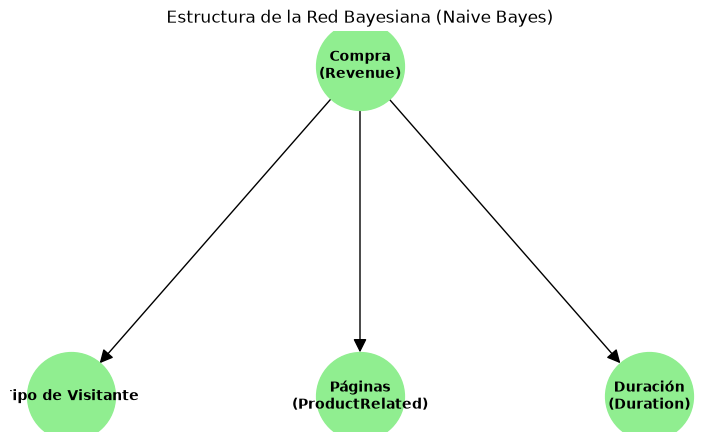

In [26]:
#7. Construimos la red Naive Bayes y estimamos la tabla de condiciones
#Unimos los datos de categorizacion y la clase para los conteos cruzados
df_nb = X_train_cat.copy()
df_nb['Revenue']=y_train

def calcular_tabla_Laplace(df,variable_hijo,clase='Revenue'):
        conteos=pd.crosstab(df[variable_hijo],df[clase])
        
        #Suavizacion de LAplace: Sumar 1 a todo
        conteos_suavizados = conteos + 1
        #Calcular las probabilidad ajustabdi los nuevos totales por columnas
        probabilidades= conteos_suavizados.div(conteos_suavizados.sum(axis=0),axis=1)
        return probabilidades
    
    
# Generar las tres tablas requeridas
tabla_visitor = calcular_tabla_Laplace(df_nb, 'VisitorType')
tabla_pages = calcular_tabla_Laplace(df_nb, 'ProductRelated')
tabla_duration = calcular_tabla_Laplace(df_nb, 'ProductRelated_Duration')

print("--- Tabla Condicional: VisitorType | Compra ---")
print(tabla_visitor)
print("\n--- Tabla Condicional: ProductRelated (Páginas categorizadas) | Compra ---")
print(tabla_pages)
print("\n--- Tabla Condicional: ProductRelated_Duration (Duración categorizada) | Compra ---")
print(tabla_duration)

# Dibujar el grafo de la estructura Naive Bayes
plt.figure(figsize=(7, 4))
G = nx.DiGraph()

# Agregar las flechas desde el padre hacia los hijos
enlaces = [
    ('Compra\n(Revenue)', 'Tipo de Visitante'),
    ('Compra\n(Revenue)', 'Páginas\n(ProductRelated)'),
    ('Compra\n(Revenue)', 'Duración\n(Duration)')
]
G.add_edges_from(enlaces)


# Definir posiciones manuales para el esquema del mapa
pos = {
    'Compra\n(Revenue)': (0.5, 1),
    'Tipo de Visitante': (0, 0),
    'Páginas\n(ProductRelated)': (0.5, 0),
    'Duración\n(Duration)': (1, 0)
}

nx.draw(G, pos, with_labels=True, node_size=4000, node_color='lightgreen', 
        font_size=10, font_weight='bold', arrows=True, arrowsize=20)
plt.title("Estructura de la Red Bayesiana (Naive Bayes)")
plt.show()

### 8. Consultas Progresivas en la Red Naive Bayes
Se implementa un sistema de inferencia probabilística que evalúa el cambio en la probabilidad de compra (`Revenue = True`) conforme se añade evidencia a la red. 
El cálculo parte de la probabilidad *a priori* de compra y se actualiza multiplicando las probabilidades condicionales obtenidas de las tablas con suavizado de Laplace, normalizando los resultados en cada paso para obtener porcentajes interpretables.

In [32]:
# 8. Inferencia y consultas progresivas
# Probabilidad a priori de la clase
p_compra = df_nb['Revenue'].value_counts(normalize=True)[True]
p_no_compra = df_nb['Revenue'].value_counts(normalize=True)[False]

def consulta_progresiva(visitante, paginas, duracion):
    print("--- Evaluando Perfil Paso a Paso ---")
    print(f"Perfil: {visitante} | Paginas: {paginas} | Duracion: {duracion} \n")
    
    # 1. Evidencia: Solo Tipo Visitante (¡Corregido tabla_visitor!)
    p_c_v = tabla_visitor.loc[visitante, True] * p_compra
    p_nc_v = tabla_visitor.loc[visitante, False] * p_no_compra
    prob1 = p_c_v / (p_c_v + p_nc_v)
    print(f"1. Probabilidad solo con VisitorType: {prob1*100:.2f}%")
    
    # 2. Evidencia: Tipo Visitante + Paginas
    p_c_vp = tabla_pages.loc[paginas, True] * p_c_v
    p_nc_vp = tabla_pages.loc[paginas, False] * p_nc_v
    prob2 = p_c_vp / (p_c_vp + p_nc_vp)
    print(f"2. Probabilidad sumando ProductRelated: {prob2*100:.2f}%")
    
    # 3. Evidencia: Tipo Visitante + Paginas + Duracion (¡Variables cruzadas corregidas!)
    p_c_vpd = tabla_duration.loc[duracion, True] * p_c_vp
    p_nc_vpd = tabla_duration.loc[duracion, False] * p_nc_vp
    prob3 = p_c_vpd / (p_c_vpd + p_nc_vpd)
    print(f"3. Probabilidad final sumando Duracion: {prob3*100:.2f}%")

# Prueba
consulta_progresiva(visitante='Returning_Visitor', paginas='Alto', duracion='Alto')

--- Evaluando Perfil Paso a Paso ---
Perfil: Returning_Visitor | Paginas: Alto | Duracion: Alto 

1. Probabilidad solo con VisitorType: 13.97%
2. Probabilidad sumando ProductRelated: 20.92%
3. Probabilidad final sumando Duracion: 30.88%


### 9. Entrenamiento de Modelos de Machine Learning
En esta fase se entrenan dos modelos utilizando la versión numérica y estandarizada de los datos (`X_train_num`):

1. **Random Forest:** Un ensamble de árboles de decisión que evaluará múltiples subconjuntos de datos.
2. **Red Neuronal Multicapa (MLP):** Se configura activando la "parada temprana" (`early_stopping=True`). Esta técnica reserva internamente una fracción del entrenamiento para validación y detiene el aprendizaje automáticamente cuando el modelo deja de mejorar, previniendo así el sobreajuste.

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# 9. Configurcion y Entrenamiento de los Modelos
print("--- Iniciando entrenamiento de modelos ---")

#Configurar y entrenar Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_num , y_train)
print("Random FOrest entrenado exitosamente")

#Configurar y entrenar Red Neuronal (MLP) con parada temprana(Early Stopping)

mlp_model= MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.1, #Usa 10% del entrenamiento para monitorear el sobreajuste
    random_state=42
)

mlp_model.fit(X_train_num , y_train)
print("Red Neuronal (MLP) entrenado exitosamnete")

--- Iniciando entrenamiento de modelos ---
Random FOrest entrenado exitosamente
Red Neuronal (MLP) entrenado exitosamnete


### 10. Evaluación Final y Comparación de Modelos
En esta última etapa, se evalúa el rendimiento de los modelos utilizando el 20% de los datos reservados para prueba (`X_test_num`). Se utiliza el umbral de clasificación por defecto (0.50).

Para validar la utilidad del Random Forest y la Red Neuronal (MLP), sus resultados (Matriz de confusión, Precisión, Sensibilidad y F1-Score) se comparan contra un **Modelo Base de Referencia**. Este modelo base representa una estrategia nula: asume que ninguna sesión terminará en compra, prediciendo siempre la clase mayoritaria (`False`).

In [36]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# 10. Evalur con el conjunto de prueba (20%)
print("--- Generando Predicciones en el Conjunto de Prueb")

#Por Defecto, .predict() clasifica usando un umbral de probabilidad de 0.50
rf_preds = rf_model.predict(X_test_num)
mlp_preds= mlp_model.predict(X_test_num)

#Modelo Base - Recordar que la mayoria es Falso
base_preds = [False] * len(y_test)

def mostrar_metricas(nombre_modelo, y_verdadero,y_predicho):
    print(f"\n=========================================")
    print(f"Resultado: {nombre_modelo}")
    print("============================================")
    
    #Confusion_matrix genera una tabla que permite ver en que se equivoca el modelo
    cm = confusion_matrix(y_verdadero , y_predicho) 
    print("Matrix de Confusion:")
    
    # Formato visual simple para la matriz_division=0 para evitar advertencias en el modelo
    print(f"                 Predice NO(0)   Predice SÍ(1)")
    print(f"Realmente NO(0) |     {cm[0][0]:<8} | {cm[0][1]:<8} |")
    print(f"Realmente SÍ(1) |     {cm[1][0]:<8} | {cm[1][1]:<8} |")
    
    #Calcular metricas con zero_division=0 para evitar advertencias en el modelo base
    precision=precision_score(y_verdadero, y_predicho , zero_division=0)
    sensibilidad = recall_score(y_verdadero, y_predicho, zero_division=0)
    f1=f1_score(y_verdadero,y_predicho,zero_division=0)
    
    print(f"\nPrecisión (Precision):   {precision:.4f}")
    print(f"Sensibilidad (Recall):   {sensibilidad:.4f}")
    print(f"Puntuación F1 (F1-Score):{f1:.4f}")
    
#Ejecutar la evalucaion
mostrar_metricas("Modelo Base (Siempre NO compra) ",y_test,base_preds)
mostrar_metricas("Random Forest",y_test,rf_preds)
mostrar_metricas("Puntuacion F1 (F1-Score)",y_test,rf_preds)

--- Generando Predicciones en el Conjunto de Prueb

Resultado: Modelo Base (Siempre NO compra) 
Matrix de Confusion:
                 Predice NO(0)   Predice SÍ(1)
Realmente NO(0) |     2084     | 0        |
Realmente SÍ(1) |     382      | 0        |

Precisión (Precision):   0.0000
Sensibilidad (Recall):   0.0000
Puntuación F1 (F1-Score):0.0000

Resultado: Random Forest
Matrix de Confusion:
                 Predice NO(0)   Predice SÍ(1)
Realmente NO(0) |     1879     | 205      |
Realmente SÍ(1) |     320      | 62       |

Precisión (Precision):   0.2322
Sensibilidad (Recall):   0.1623
Puntuación F1 (F1-Score):0.1911

Resultado: Puntuacion F1 (F1-Score)
Matrix de Confusion:
                 Predice NO(0)   Predice SÍ(1)
Realmente NO(0) |     1879     | 205      |
Realmente SÍ(1) |     320      | 62       |

Precisión (Precision):   0.2322
Sensibilidad (Recall):   0.1623
Puntuación F1 (F1-Score):0.1911
